In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import pyarrow
from pathlib import Path

In [2]:
BASE_DIR = Path.cwd().resolve().parent
DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "raw"

In [3]:
df_cap200ab = pd.read_parquet(RAW_DIR / "03_CAP200AB.parquet")
df_caratula = pd.read_parquet(RAW_DIR / "CARATULA.parquet")

In [4]:
ruta_mapa = BASE_DIR / "data"/"processed"/"LIM_DEPARTAMENTAL_PERU_MIN.json"
ruta_provinvial = BASE_DIR / "data"/"processed"/"LIM_PROVINCIAL_PERU.json"
peru = gpd.read_file(ruta_mapa)
provincias_peru = gpd.read_file(ruta_provinvial)

In [10]:
df_cap200ab["P219_EQUIV_KG"] = pd.to_numeric(
    df_cap200ab["P219_EQUIV_KG"],
    errors="coerce"
)

In [11]:
df_cap200ab.info(verbose = True)

<class 'pandas.DataFrame'>
RangeIndex: 165711 entries, 0 to 165710
Data columns (total 127 columns):
 #    Column            Dtype  
---   ------            -----  
 0    ANIO              string 
 1    CCDD              string 
 2    NOMBREDD          string 
 3    CCPP              string 
 4    NOMBREPV          string 
 5    CCDI              string 
 6    NOMBREDI          string 
 7    NSEGM             string 
 8    ID_PROD           string 
 9    UA                string 
 10   RESFIN            string 
 11   REGION            string 
 12   ESTRATO           string 
 13   FACTOR_PRODUCTOR  string 
 14   CODIGO            string 
 15   P101A             string 
 16   P142_1            string 
 17   P142_2            string 
 18   P105              string 
 19   P147              string 
 20   P203              string 
 21   P204_NOM          string 
 22   P204_COD          string 
 23   P204_TIPO         string 
 24   P205_N            string 
 25   P205_TOT          string 
 26

# 1. Agrupación de datos según la variable P219_EQUIV_KG usando mapas coropletas

## 1.1. Perú

In [12]:
resumen = df_cap200ab.groupby("NOMBREDD")["P219_EQUIV_KG"].agg(
    total_kg = "sum",
    promedio = "mean",
    n = "size",
    mediana = "median"
).reset_index().round(2)

resumen.head(10)

,NOMBREDD,total_kg,promedio,n,mediana
0,AMAZONAS,2844036.6,420.28,6767,50.0
1,ANCASH,1371875.4,116.55,11771,18.0
2,APURIMAC,233610.5,35.35,6609,11.5
3,AREQUIPA,1256290.61,141.05,8907,1.0
4,AYACUCHO,1097947.38,85.76,12802,18.0
5,CAJAMARCA,3787982.49,227.32,16664,15.0
6,CALLAO,1038.0,173.0,6,3.5
7,CUSCO,933461.56,74.03,12610,11.5
8,HUANCAVELICA,307094.3,39.18,7839,18.0
9,HUANUCO,1336936.75,139.19,9605,11.5


In [ ]:
#Unimos los datos del mapa de Peru y los datos del resumen de la produccion esperada por las unidades agropecuarias 

In [13]:
peru_merge = peru.merge(
    resumen,
    left_on= "NOMBDEP",
    right_on = "NOMBREDD",
    how="left"
).copy()

In [ ]:
peru_merge.info()

In [ ]:
#Ahora graficamos el mapa cloroperico de todo el peru con respecto a la variable expectativa de producción(P219_EQUIV_KG) de parte de las unidades

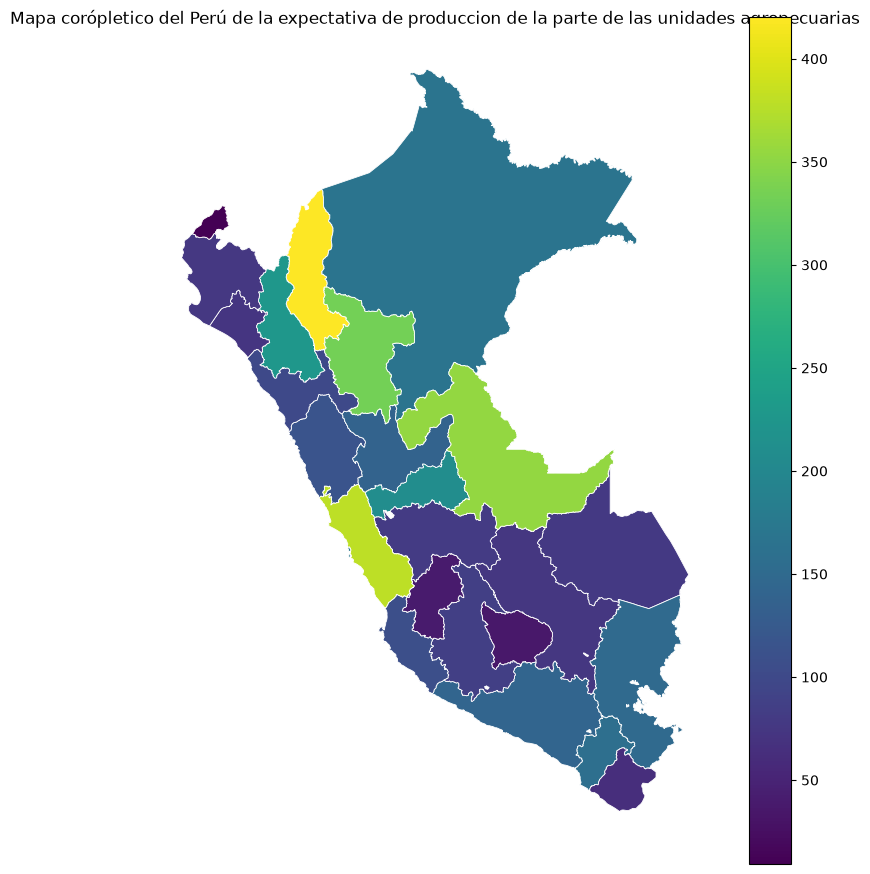

In [15]:
fix, ax = plt.subplots(figsize = (9,11))

peru_merge.plot(
    column="promedio",
    cmap= "viridis",
    legend= True,
    edgecolor= "white",
    linewidth= 0.6,
    ax = ax
)

ax.set_title("Mapa corópletico del Perú de la expectativa de produccion de la parte de las unidades agropecuarias")
ax.set_axis_off()
plt.show()

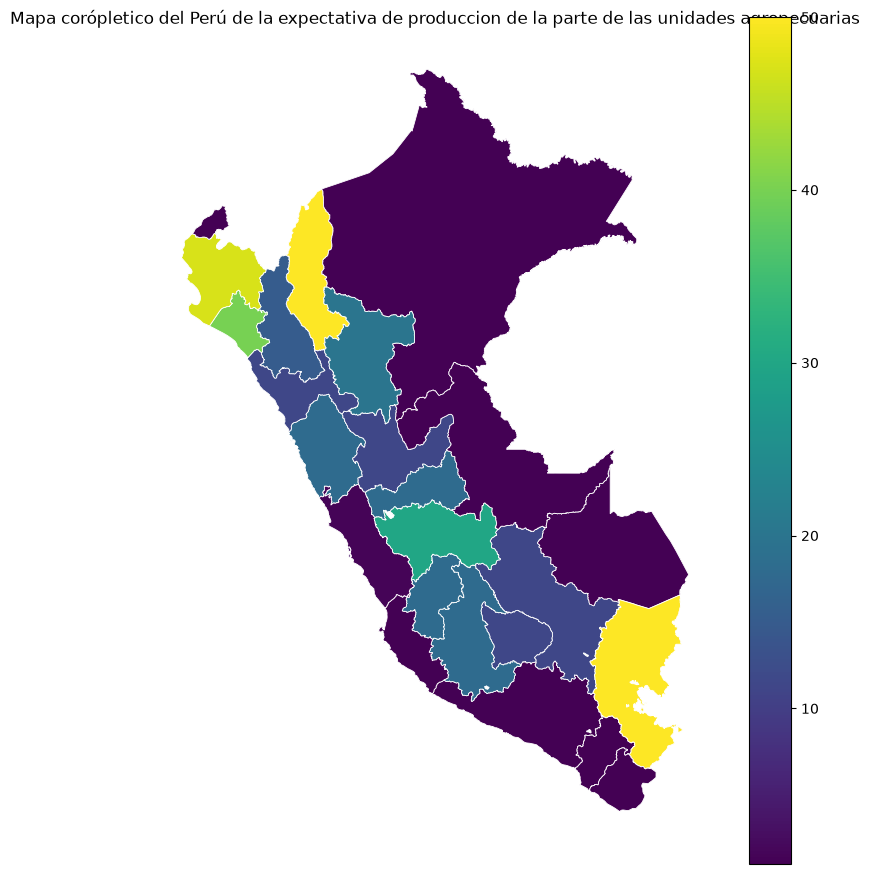

In [9]:
fix, ax = plt.subplots(figsize = (9,11))

peru_merge.plot(
    column="mediana",
    cmap= "viridis",
    legend= True,
    edgecolor= "white",
    linewidth= 0.6,
    ax = ax
)

ax.set_title("Mapa corópletico del Perú de la expectativa de produccion de la parte de las unidades agropecuarias")
ax.set_axis_off()
plt.show()

In [ ]:
#Que necesito para hacer un mapacloroplético de la expectativa de la producción en la región lima
#Filtrar el geoJson solamente por el mapa de la region de Lima
#

# 1.2. Lambayeque

In [19]:
provincias = provincias_peru.copy()
provinvias_lam = provincias_peru[
    provincias_peru["NOMBDEP"].str.upper().eq("LAMBAYEQUE")
]
provinvias_lam.head(3)

,OBJECTID_1,OBJECTID,CCDD,NOMBDEP,CCPP,NOMBPROV,CAPITAL,IDPROV,Shape_STAr,Shape_STLe,ORIG_FID,Shape_Leng,Shape_Area,geometry
189,200,190,14,LAMBAYEQUE,01,CHICLAYO,CHICLAYO,1401,0.272214,3.030573,189,3.030573,0.272214,"POLYGON ((-79.22906 -6.67141, -79.23107 -6.672..."
190,201,191,14,LAMBAYEQUE,02,FERREÑAFE,FERREÑAFE,1402,0.128699,3.091058,190,3.091058,0.128699,"POLYGON ((-79.21321 -6.09887, -79.21278 -6.099..."
191,202,192,14,LAMBAYEQUE,03,LAMBAYEQUE,LAMBAYEQUE,1403,0.784081,4.877186,191,4.877186,0.784081,"POLYGON ((-79.83944 -5.63003, -79.83999 -5.629..."


In [20]:
df_lambayeque = df_cap200ab[df_cap200ab["NOMBREDD"]=="LAMBAYEQUE"].copy()

In [29]:
print(df_lambayeque["NOMBREPV"].unique())
print(provinvias_lam["NOMBPROV"].unique())

<ArrowStringArray>
['LAMBAYEQUE', 'FERRENAFE', 'CHICLAYO']
Length: 3, dtype: string
<ArrowStringArray>
['CHICLAYO', 'FERRENAFE', 'LAMBAYEQUE']
Length: 3, dtype: str


In [21]:
df_lambayeque["NOMBREPV"] = df_lambayeque["NOMBREPV"].replace(
    "FERREÃ‘AFE", "FERRENAFE"
)

provinvias_lam["NOMBPROV"] = provinvias_lam["NOMBPROV"].replace(
    "FERREÑAFE", "FERRENAFE"
)

In [22]:
df_lambayeque.head(10)

,ANIO,CCDD,NOMBREDD,CCPP,NOMBREPV,CCDI,NOMBREDI,NSEGM,ID_PROD,UA,...,P223A,P223B_1,P223B_2,P223B_3,P223B_4,P223B_5,P223B_6,P223B_7,P223B_8,OMICAP200
50996,2024,14.0,LAMBAYEQUE,3.0,LAMBAYEQUE,11.0,SAN JOSE,13084,1,1,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,
50997,2024,14.0,LAMBAYEQUE,3.0,LAMBAYEQUE,11.0,SAN JOSE,13084,1,1,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,
50998,2024,14.0,LAMBAYEQUE,3.0,LAMBAYEQUE,11.0,SAN JOSE,13084,1,1,...,2.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,
50999,2024,14.0,LAMBAYEQUE,3.0,LAMBAYEQUE,11.0,SAN JOSE,13084,1,1,...,2.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,
51000,2024,14.0,LAMBAYEQUE,3.0,LAMBAYEQUE,11.0,SAN JOSE,13084,2,2,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,
51001,2024,14.0,LAMBAYEQUE,3.0,LAMBAYEQUE,11.0,SAN JOSE,13084,3,3,...,2.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,
51002,2024,14.0,LAMBAYEQUE,3.0,LAMBAYEQUE,11.0,SAN JOSE,13084,6,6,...,2.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,
51003,2024,14.0,LAMBAYEQUE,3.0,LAMBAYEQUE,11.0,SAN JOSE,13084,7,7,...,2.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,
51004,2024,14.0,LAMBAYEQUE,3.0,LAMBAYEQUE,11.0,SAN JOSE,13084,7,7,...,2.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,
51005,2024,14.0,LAMBAYEQUE,3.0,LAMBAYEQUE,11.0,SAN JOSE,13084,7,7,...,2.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,


In [24]:
resumen_lam = df_lambayeque.groupby("NOMBREPV")["P219_EQUIV_KG"].agg(
    total_kg = "sum",
    promedio = "mean",
    n = "size",
    mediana = "median"
).reset_index().round(2)

resumen_lam.head(3)

,NOMBREPV,total_kg,promedio,n,mediana
0,CHICLAYO,54970.27,115.24,477,50.0
1,FERRENAFE,66962.3,101.92,657,35.0
2,LAMBAYEQUE,55833.52,42.95,1300,40.0


In [25]:
lam_merge = provinvias_lam.merge(
    resumen_lam,
    left_on= "NOMBPROV",
    right_on = "NOMBREPV",
    how="left"
).copy()

In [26]:
lam_merge

,OBJECTID_1,OBJECTID,CCDD,NOMBDEP,CCPP,NOMBPROV,CAPITAL,IDPROV,Shape_STAr,Shape_STLe,ORIG_FID,Shape_Leng,Shape_Area,geometry,NOMBREPV,total_kg,promedio,n,mediana
0,200,190,14,LAMBAYEQUE,01,CHICLAYO,CHICLAYO,1401,0.272214,3.030573,189,3.030573,0.272214,"POLYGON ((-79.22906 -6.67141, -79.23107 -6.672...",CHICLAYO,54970.27,115.24,477,50.0
1,201,191,14,LAMBAYEQUE,02,FERRENAFE,FERREÑAFE,1402,0.128699,3.091058,190,3.091058,0.128699,"POLYGON ((-79.21321 -6.09887, -79.21278 -6.099...",FERRENAFE,66962.3,101.92,657,35.0
2,202,192,14,LAMBAYEQUE,03,LAMBAYEQUE,LAMBAYEQUE,1403,0.784081,4.877186,191,4.877186,0.784081,"POLYGON ((-79.83944 -5.63003, -79.83999 -5.629...",LAMBAYEQUE,55833.52,42.95,1300,40.0


In [27]:
lam_merge[
    ["NOMBDEP", "NOMBPROV", "total_kg", "promedio", "n", "mediana"]
]

,NOMBDEP,NOMBPROV,total_kg,promedio,n,mediana
0,LAMBAYEQUE,CHICLAYO,54970.27,115.24,477,50.0
1,LAMBAYEQUE,FERRENAFE,66962.3,101.92,657,35.0
2,LAMBAYEQUE,LAMBAYEQUE,55833.52,42.95,1300,40.0


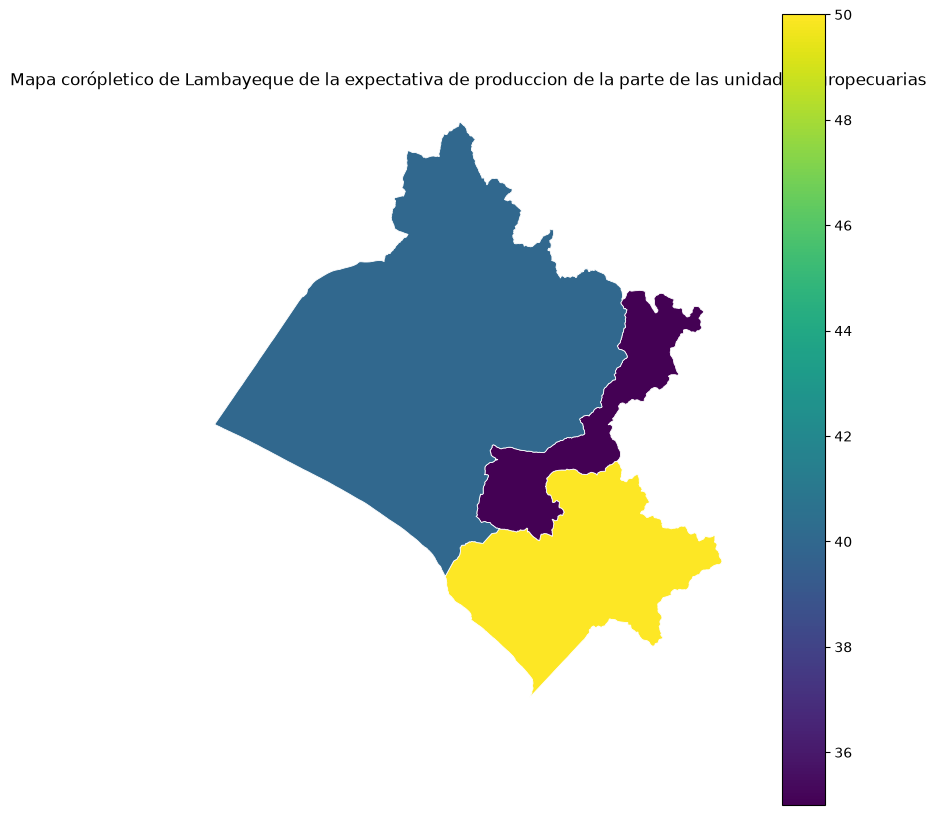

In [28]:
fix, ax = plt.subplots(figsize = (9,11))

lam_merge.plot(
    column="mediana",
    cmap= "viridis",
    legend= True,
    edgecolor= "white",
    linewidth= 0.6,
    ax = ax
)

ax.set_title("Mapa corópletico de Lambayeque de la expectativa de produccion de la parte de las unidades agropecuarias")
ax.set_axis_off()
plt.show()

In [ ]:
#¿Cuáles son los principales factores que afectaron la producción agrícola de las unidades agropecuarias de Lambayeque?
#Sí afectó: número de registros con código 1.
#No afectó: número de registros con código 0.
#Sin dato: número de registros faltantes.

In [35]:
df_cap200ab["P223A"].value_counts(dropna=False)

P223A
2.0     97775
1.0     67931
<NA>        5
Name: count, dtype: int64[pyarrow]

In [42]:
df_cap200ab["P223B_1"].value_counts(dropna=False)

P223B_1
<NA>    97780
0.0     54988
1.0     12943
Name: count, dtype: int64[pyarrow]

In [51]:
cols_factores = [f"P223B_{i}" for i in range(1, 9)]

df_lambayeque[cols_factores] = df_lambayeque[cols_factores].apply(
    pd.to_numeric,
    errors="coerce"
)

factores_lam = df_lambayeque[cols_factores]

nombres_factores = [
    "Sequía",
    "Bajas temperaturas",
    "Heladas",
    "Granizadas",
    "Friaje",
    "Lluvias a destiempo",
    "Plagas y enfermedades",
    "Otros"
]

tabla_lam = pd.DataFrame({
    "factor": nombres_factores,
    "si_afecto": [factores_lam[c].eq(1).sum() for c in cols_factores],
    "no_afecto": [factores_lam[c].eq(0).sum() for c in cols_factores]
})

tabla_lam["porcentaje_falla"] = (
    tabla_lam["si_afecto"] /
    (tabla_lam["si_afecto"] + tabla_lam["no_afecto"]) * 100
).round(2)

tabla_lam

,factor,si_afecto,no_afecto,porcentaje_falla
0,Sequía,247,598,29.23
1,Bajas temperaturas,19,826,2.25
2,Heladas,9,836,1.07
3,Granizadas,0,845,0.00
4,Friaje,3,842,0.36
5,Lluvias a destiempo,43,802,5.09
6,Plagas y enfermedades,563,282,66.63
7,Otros,54,791,6.39
